In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/mlp-kaggle-assignment-2-may-2026-term/sample_submission.csv
/kaggle/input/competitions/mlp-kaggle-assignment-2-may-2026-term/train.csv
/kaggle/input/competitions/mlp-kaggle-assignment-2-may-2026-term/test.csv


# Load data

In [2]:
import pandas as pd
submition = pd.read_csv("/kaggle/input/competitions/mlp-kaggle-assignment-2-may-2026-term/sample_submission.csv")
train = pd.read_csv("/kaggle/input/competitions/mlp-kaggle-assignment-2-may-2026-term/train.csv")
test = pd.read_csv("/kaggle/input/competitions/mlp-kaggle-assignment-2-may-2026-term/test.csv")

In [3]:
# verify the data
train.head()

,id,customer_id,last_name,credit_score,country,gender,age,tenure,acc_balance,prod_count,has_card,is_active,estimated_salary,exit_status
0,0,15788291,Iredale,559.0,France,Male,28.0,1,149989.39,1.0,1.0,1.0,67622.46,0
1,1,15642816,Hs?,694.0,France,Female,37.0,7,114510.35,2.0,0.0,0.0,182797.86,0
2,2,15632272,T'ien,585.0,NaN,Female,45.0,8,NaN,2.0,1.0,1.0,170338.35,0
3,3,15685826,Hightower,589.0,Spain,Male,25.0,0,166082.18,1.0,1.0,1.0,166476.46,0
4,4,15658032,Hopkins,701.0,France,Male,39.0,2,0.00,2.0,1.0,0.0,82526.92,0


# Identify data types of different columns

In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90000 entries, 0 to 89999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                90000 non-null  int64  
 1   customer_id       90000 non-null  int64  
 2   last_name         90000 non-null  object 
 3   credit_score      80444 non-null  float64
 4   country           83979 non-null  object 
 5   gender            90000 non-null  object 
 6   age               90000 non-null  float64
 7   tenure            90000 non-null  int64  
 8   acc_balance       82743 non-null  float64
 9   prod_count        85137 non-null  float64
 10  has_card          90000 non-null  float64
 11  is_active         90000 non-null  float64
 12  estimated_salary  90000 non-null  float64
 13  exit_status       90000 non-null  int64  
dtypes: float64(7), int64(4), object(3)
memory usage: 9.6+ MB


# descriptive statistics of numerical columns

In [5]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
id,90000.0,4.499950e+04,25980.906451,0.00,22499.75,44999.50,6.749925e+04,89999.00
customer_id,90000.0,1.569209e+07,71297.959941,15565701.00,15633608.00,15690164.00,1.575674e+07,15815690.00
credit_score,80444.0,6.564971e+02,80.016856,350.00,597.00,659.00,7.100000e+02,850.00
age,90000.0,3.811953e+01,8.855203,18.00,32.00,37.00,4.200000e+01,92.00
tenure,90000.0,5.017022e+00,2.804813,0.00,3.00,5.00,7.000000e+00,10.00
acc_balance,82743.0,5.545673e+04,62788.474236,0.00,0.00,0.00,1.198258e+05,250898.09
prod_count,85137.0,1.552932e+00,0.548011,1.00,1.00,2.00,2.000000e+00,4.00
has_card,90000.0,7.542889e-01,0.430510,0.00,1.00,1.00,1.000000e+00,1.00
is_active,90000.0,4.971778e-01,0.499995,0.00,0.00,0.00,1.000000e+00,1.00
estimated_salary,90000.0,1.123947e+05,50360.440702,11.58,74430.36,117505.07,1.548748e+05,199992.48


# Identify and handle the missing values

In [6]:
train.isnull().sum()

id                     0
customer_id            0
last_name              0
credit_score        9556
country             6021
gender                 0
age                    0
tenure                 0
acc_balance         7257
prod_count          4863
has_card               0
is_active              0
estimated_salary       0
exit_status            0
dtype: int64

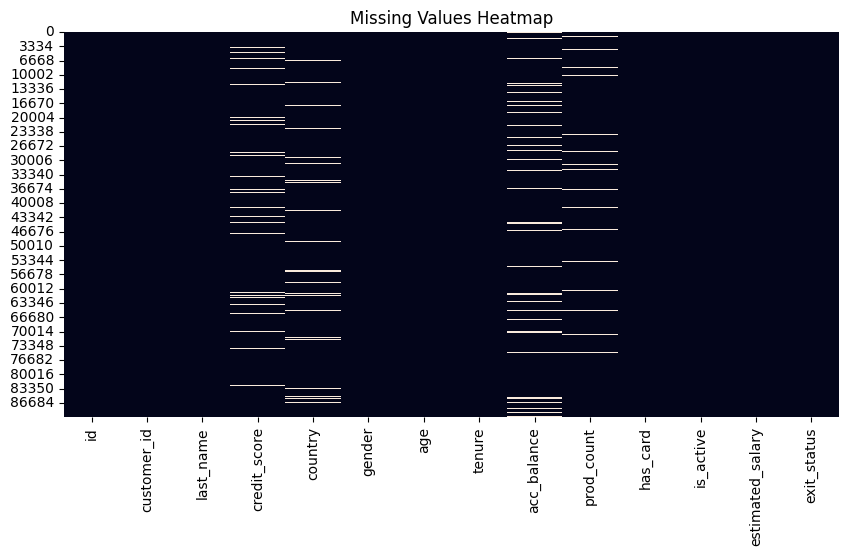

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
sns.heatmap(train.isnull(), cbar=False)
plt.title("Missing Values Heatmap")
plt.show()

In [8]:
train

,id,customer_id,last_name,credit_score,country,gender,age,tenure,acc_balance,prod_count,has_card,is_active,estimated_salary,exit_status
0,0,15788291,Iredale,559.0,France,Male,28.0,1,149989.39,1.0,1.0,1.0,67622.46,0
1,1,15642816,Hs?,694.0,France,Female,37.0,7,114510.35,2.0,0.0,0.0,182797.86,0
2,2,15632272,T'ien,585.0,NaN,Female,45.0,8,NaN,2.0,1.0,1.0,170338.35,0
3,3,15685826,Hightower,589.0,Spain,Male,25.0,0,166082.18,1.0,1.0,1.0,166476.46,0
4,4,15658032,Hopkins,701.0,France,Male,39.0,2,0.00,2.0,1.0,0.0,82526.92,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89995,89995,15609187,Cox,455.0,France,Female,36.0,10,155879.09,3.0,0.0,0.0,70774.97,1
89996,89996,15801462,Yermakov,678.0,Germany,Male,31.0,8,109578.04,2.0,0.0,1.0,51503.51,0
89997,89997,15584766,Knight,530.0,France,Male,31.0,1,NaN,1.0,1.0,0.0,2382.61,1
89998,89998,15671409,Scott,743.0,Germany,Female,28.0,8,151027.06,2.0,0.0,0.0,168814.48,0


In [9]:
import numpy as np
num_cols = train.select_dtypes(include=np.number).columns
num_cols

Index(['id', 'customer_id', 'credit_score', 'age', 'tenure', 'acc_balance',
       'prod_count', 'has_card', 'is_active', 'estimated_salary',
       'exit_status'],
      dtype='object')

In [10]:
# fill the numarical missing values with the median

train.credit_score.fillna(train.credit_score.median(),inplace = True)
train.acc_balance.fillna(train.acc_balance.median(),inplace = True)
train.prod_count.fillna(train.prod_count.median(),inplace = True)
print("Numarical missing values has been replaced by median")

Numarical missing values has been replaced by median


/tmp/ipykernel_16/3639784773.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  train.credit_score.fillna(train.credit_score.median(),inplace = True)
/tmp/ipykernel_16/3639784773.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inp

In [11]:
# replace the country missing values with the unknown
train.country.fillna("UNKNOWN",inplace=True)
print("Country missing values has been replaced by unknown")

Country missing values has been replaced by unknown


/tmp/ipykernel_16/1624852443.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  train.country.fillna("UNKNOWN",inplace=True)


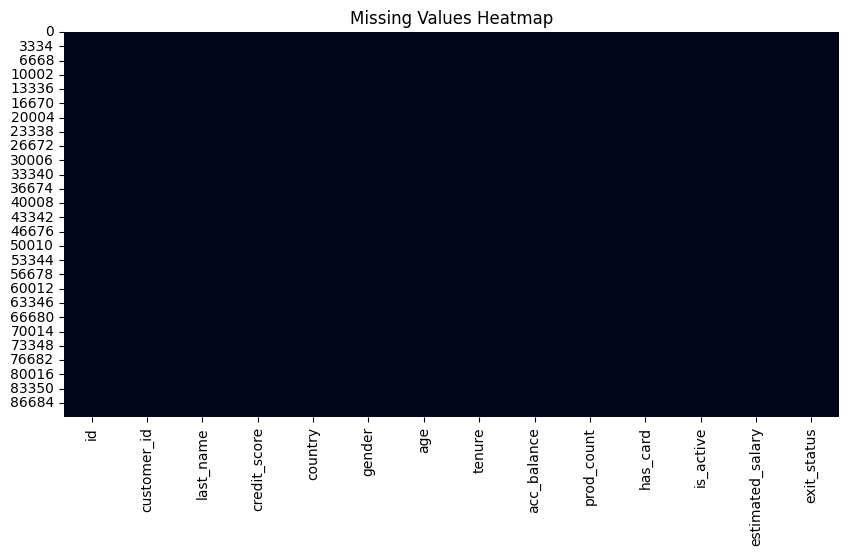

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
sns.heatmap(train.isnull(), cbar=False)
plt.title("Missing Values Heatmap")
plt.show()


# Identify and handle missing values

In [13]:
duplicated_items = train.duplicated().sum()
if duplicated_items > 0:
    print("removing duplicated items")
    train = train.drop_duplicates()
else:
    print("no duplicates found!")

no duplicates found!


# identify and handle outliers

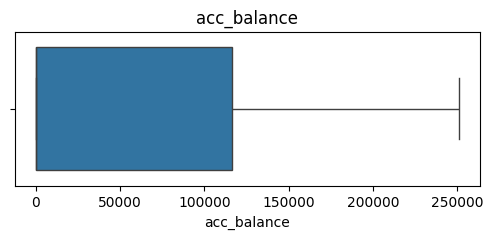

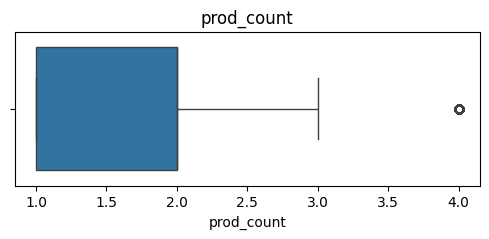

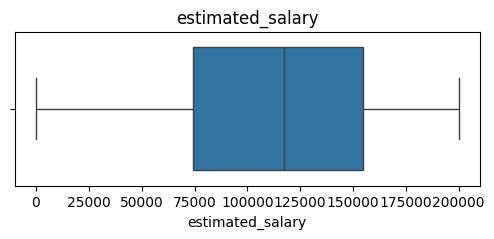

In [14]:
import seaborn as sns 
import matplotlib.pyplot as plt
cols = ["acc_balance","prod_count","estimated_salary"]
for col in ["acc_balance","prod_count","estimated_salary"]:
    plt.figure(figsize=(6,2))
    sns.boxplot(x=train[col])
    plt.title(col)
    plt.show()

In [15]:
for col in ["acc_balance","prod_count","estimated_salary"]:

    Q1 = train[col].quantile(0.25)
    Q3 = train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = train[
        (train[col] < lower) |
        (train[col] > upper)
    ]

    print(f"{col}: {len(outliers)} outliers")

acc_balance: 0 outliers
prod_count: 263 outliers
estimated_salary: 0 outliers


- as there are minimal number of outliers we can keep them.

# Visualizations and insights

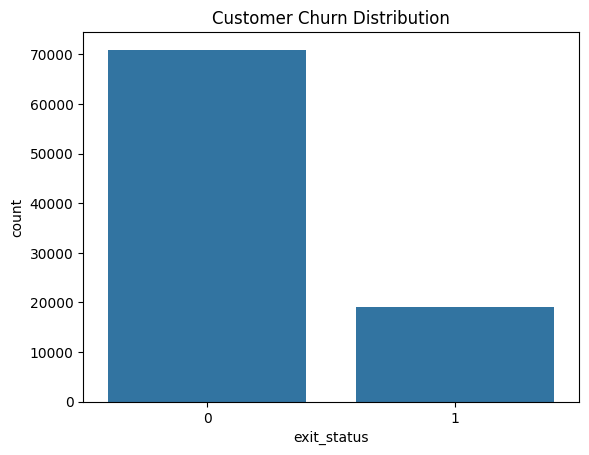

In [16]:
sns.countplot(x="exit_status", data=train)
plt.title("Customer Churn Distribution")
plt.show()

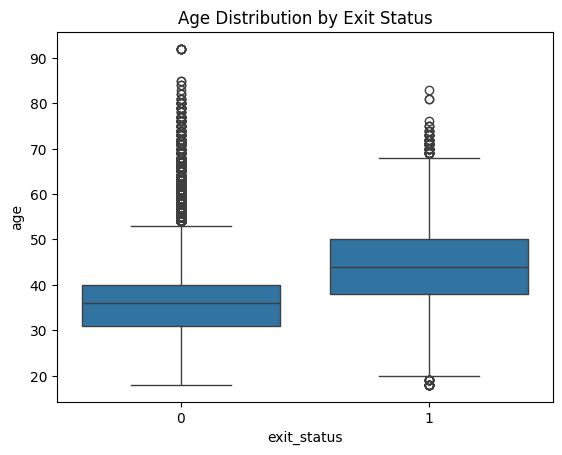

In [17]:
sns.boxplot(x="exit_status", y="age", data=train)
plt.title("Age Distribution by Exit Status")
plt.show()